# Amostragem combinatória de ASTs e cobertura de skeletons

**Objetivo:** calcular as probabilidades a partir da quantidade de ASTs válidas e comparar com o melhor resultado anterior: **24.033 skeletons distintos em 50.000 árvores**, obtido com probabilidades fixas e prior exponencial para a quantidade de operações.

O [notebook 2](../2_random_ast_distribution.ipynb) distingue o número de ASTs, o dicionário de monômios e os skeletons observados. Com uma série, 12 lags e grau máximo quatro, existem 1.820 monômios possíveis, incluindo a constante. A potência $2^{1820}$ conta todos os subconjuntos desse dicionário e inclui muitos skeletons fora do alcance de uma AST com até seis operadores. Nesta comparação usamos a quantidade observada de skeletons distintos e a cobertura do dicionário de monômios.

**Novo método:** contagem exata de completamentos por programação dinâmica, seguida de sorteio uniforme de um índice inteiro e reconstrução da AST correspondente. Cada AST discreta válida recebe a mesma probabilidade. A canonização continua sendo aplicada depois da geração; árvores com o mesmo skeleton continuam podendo aparecer várias vezes. Os coeficientes contínuos são sorteados após a estrutura.

O [experimento anterior](../exponential_operator_prior/1_exponential_operator_coverage.ipynb) é reexecutado como referência. Acrescentamos um controle com o mesmo tamanho de árvore do método combinatório e as probabilidades antigas de folhas e operadores.

## 1. O que é contado e o que significa “melhor”

Se há $S$ séries e $L$ lags admissíveis, há $M=SL$ átomos distintos, como $(0,1)$ para $x_0(t-1)$. Cada folha pode ser um desses $M$ átomos ou um marcador de parâmetro. Cada ocorrência de parâmetro recebe posteriormente seu próprio coeficiente contínuo, com magnitude uniforme entre 0,05 e 0,90 e sinal equiprovável. Os nomes dos slots são definidos pela posição na árvore; renomeá-los não cria outra estrutura. A ordem esquerda/direita é preservada.

Sem o teto de grau, o número de ASTs com $n$ operadores e pelo menos um lag seria
\[
N_n=C_n\,2^n\big[(M+1)^{n+1}-1\big],\qquad
C_n=\frac{1}{n+1}\binom{2n}{n}.
\]
$C_n$ conta formatos binários ordenados; $2^n$ escolhe soma ou produto em cada operador; o último fator escolhe os rótulos das folhas e exclui a árvore composta somente por parâmetros. A presença do teto de grau exige uma contagem mais detalhada.

A distribuição uniforme maximiza a diversidade esperada de **ASTs** num espaço finito, sob sorteio independente com reposição. Nosso objetivo prático é a diversidade de **skeletons**: se $p_s$ é a probabilidade do skeleton $s$, o número esperado de skeletons distintos após $N$ sorteios é
\[
\mathbb{E}[D_N]=\sum_s \left[1-(1-p_s)^N\right].
\]
A função é côncava em $p_s$ para $N>1$; entre distribuições livres num conjunto fixo de skeletons, a uniforme maximiza essa expectativa. Entretanto, com ASTs uniformes, $p_s$ depende de quantas ASTs resultam em $s$. O método abaixo fornece probabilidades exatas para explorar ASTs válidas; sua qualidade para skeletons será medida. A contagem exata de classes equivalentes de skeletons permanece uma questão separada.

## 2. Recorrência que determina as probabilidades

Seja $T_{n,d}$ a quantidade de ASTs com $n$ operadores e grau estrutural $d$, antes de substituir os coeficientes. Para uma folha, $T_{0,0}=1$ e $T_{0,1}=M$. Para $n\geq1$:
\[
T_{n,d}=\sum_{i=0}^{n-1}\sum_{a=0}^{D}\sum_{b=0}^{D}
T_{i,a}T_{n-1-i,b}
\left[\mathbf{1}_{\max(a,b)=d}+\mathbf{1}_{a+b=d}\right],\quad 0\leq d\leq D.
\]
A soma usa o maior grau dos filhos; o produto soma os graus. Se os dois operadores levam ao mesmo grau, ambos contam, pois são ASTs diferentes. O cálculo mantém apenas estados com grau até $D=4$.

Depois calculamos $A_n=\sum_{d=1}^{D}T_{n,d}$, pois exigimos pelo menos um lag. O tamanho recebe probabilidade
\[
P(K=n)=\frac{A_n}{\sum_{j=1}^{6} A_j}.
\]
Em cada estado $(n,d)$, uma escolha de operador, divisão de tamanhos e graus dos filhos recebe probabilidade $T_{i,a}T_{n-1-i,b}/T_{n,d}$. Assim, as probabilidades de soma, produto e terminais dependem do estado que falta construir. As médias globais calculadas adiante resumem o resultado dessa regra; usar somente essas médias como probabilidades fixas produziria outra distribuição.

Por indução, se cada filho é uniforme na sua classe, uma árvore específica nesse estado tem probabilidade $(T_{i,a}T_{n-1-i,b}/T_{n,d})(1/T_{i,a})(1/T_{n-1-i,b})=1/T_{n,d}$. O sorteio do estado da raiz proporcional à sua contagem estende essa uniformidade ao conjunto inteiro de ASTs admitidas.

Na implementação, um inteiro uniforme entre zero e a quantidade total de ASTs menos um identifica a árvore. Intervalos de índices representam as alternativas; quociente e resto identificam os filhos. Essa reconstrução por índice (`unranking`) usa contagens inteiras exatas e evita arredondar pesos muito grandes.

**Fundamentação:** a escolha proporcional à quantidade de completamentos segue o método recursivo de geração combinatória de Flajolet, Zimmermann e Van Cutsem (1994), registrado em `references/library.bib` como `flajolet1994calculus`. Os [slides de Zimmermann, página 16 do PDF](https://members.loria.fr/PZimmermann/talks/pf.pdf#page=16), mostram o sorteio de uniões pelas contagens e de produtos pelos produtos das contagens. A extensão do estado com o grau polinomial é a implementação deste experimento.

In [1]:
from collections import Counter
from dataclasses import asdict, replace
from hashlib import sha256
from math import comb, exp, log
from pathlib import Path
from time import perf_counter
import platform
import subprocess
import sys

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
pd.set_option('display.max_colwidth', None)

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'pyproject.toml').exists() and (p / 'src/tsfmxai').exists())
sys.path.insert(0, str(ROOT / 'src'))
from tsfmxai.generators import (
    RandomTreeConfig, CombinatorialTreeConfig, CombinatorialTreeSampler,
    derive_sample_seed, sample_random_mechanism,
)
from tsfmxai.representations import (
    Add, Multiply, Lag, Parameter, canonicalize_polynomial, operator_count, walk,
)
from tsfmxai.representations.canonical_polynomial import format_monomial

BASE = RandomTreeConfig()
COMBINATORIAL = CombinatorialTreeConfig()
ROOT_SEED = 20261028
SAMPLE_COUNT = 50_000
CHECKPOINTS = (100, 500, 1_000, 5_000, 10_000, 20_000, 50_000)
MAX_DEGREE = 4
TOP_N = 15
EXP_SLOPE = 0.4
COUNTS = np.arange(1, 7)
EXP_WEIGHTS = np.exp(EXP_SLOPE * (COUNTS - 1))
EXP_PROBS = EXP_WEIGHTS / EXP_WEIGHTS.sum()
assert BASE.num_series == COMBINATORIAL.num_series == 1
assert BASE.maximum_lag == COMBINATORIAL.maximum_lag == 12
started = perf_counter()
sampler = CombinatorialTreeSampler(COMBINATORIAL)
INITIALIZATION_SECONDS = perf_counter() - started
profile = sampler.marginal_profile()
size_df = pd.DataFrame([
    {'Operações': n, 'ASTs válidas': count,
     'P(K) combinatória (%)': 100 * count / sampler.total_structures,
     'P(K) exponencial (%)': 100 * EXP_PROBS[n-1]}
    for n, count in sampler.size_counts().items()
])
display(size_df)
print('Perfil marginal calculado:', profile)
print('Contagens calculadas uma vez em %.6f s.' % INITIALIZATION_SECONDS)

,Operações,ASTs válidas,P(K) combinatória (%),P(K) exponencial (%)
0,1,336,8.049806e-08,4.906875
1,2,17568,4.208899e-06,7.320197
2,3,1142400,2.736934e-04,10.920450
3,4,79685760,1.909092e-02,16.291397
4,5,5692958208,1.363905e+00,24.303909
5,6,411627561984,9.861673e+01,36.257172


Perfil marginal calculado: {'mean_operators': 5.985970748173334, 'addition_fraction': 0.5719158704720906, 'parameter_fraction': 0.08689822068101058}
Contagens calculadas uma vez em 0.001016 s.


**O que foi feito:** calculamos as quantidades exatas por tamanho e as frequências globais de soma e parâmetro induzidas pela regra. O sampler reutiliza essa tabela em todas as gerações.

## 3. Validação num espaço pequeno e pseudocódigo

O teste unitário `tests/unit/test_combinatorial_expression.py` enumera independentemente todas as ASTs com até três operadores, duas séries e grau até dois; compara o conjunto inteiro com os índices reconstruídos pelo algoritmo. Também verifica a fórmula fechada sem restrição de grau, valores maiores que 64 bits, limites de configuração e independência de RNGs externos.

O exemplo abaixo mostra por que a contagem de ASTs e a contagem de skeletons diferem. Cada ocorrência de parâmetro é fixada em 0,5 apenas nesta demonstração para tornar os coeficientes reproduzíveis. A contagem de completamentos é anterior à substituição numérica.

```text
contar T[n, d] para todos os tamanhos e graus admissíveis
somar as contagens dos estados de raiz permitidos
para cada índice de amostra:
    derivar seed local
    sortear um índice inteiro uniforme no total de ASTs
    localizar o estado (n, d) e os intervalos dos filhos
    reconstruir recursivamente a AST por quociente e resto
    sortear os valores contínuos dos parâmetros
    canonizar e contar skeletons (sem remover duplicados)
```

Código reutilizável: `src/tsfmxai/generators/combinatorial_expression.py`.

In [2]:
tiny = CombinatorialTreeSampler(CombinatorialTreeConfig(
    minimum_operators=1, maximum_operators=1, maximum_lag=1,
    minimum_parameter_magnitude=0.5, maximum_parameter_magnitude=0.5,
))
tiny_counts = Counter()
for rank in range(tiny.total_structures):
    sample = tiny.unrank(rank, seed=0)
    normal = canonicalize_polynomial(sample.expression, sample.binding)
    tiny_counts[normal.skeleton] += 1

def support_formula(support):
    return ' + '.join(format_monomial(term) for term in support) or '0'

tiny_df = pd.DataFrame([
    {'Skeleton': support_formula(key), 'ASTs que geram este skeleton': value,
     'Probabilidade (%)': 100 * value / tiny.total_structures}
    for key, value in sorted(tiny_counts.items())
])
assert tiny.total_structures == 6
assert sum(tiny_counts.values()) == 6
display(tiny_df)

,Skeleton,ASTs que geram este skeleton,Probabilidade (%)
0,1 + s_0[t-1],2,33.333333
1,s_0[t-1],3,50.000000
2,s_0[t-1] * s_0[t-1],1,16.666667


**O que foi feito:** enumeramos as seis ASTs possíveis com um lag disponível e um operador. As multiplicidades de skeletons ficam visíveis mesmo quando cada AST tem a mesma chance.

## 4. Comparação com o melhor resultado anterior

**Referência:** probabilidades fixas de parâmetro/lag 0,40/0,60 e soma/produto 0,65/0,35; $P(K)\propto e^{0,4(K-1)}$. Usamos exatamente as seeds e o sorteio de $K$ do experimento anterior.

**Combinatório:** sorteio uniforme sobre todas as ASTs ordenadas contadas, com $1\leq K\leq6$, pelo menos um lag e grau até quatro. Todas as folhas de lag recebem um dos 12 rótulos série–lag contados. A classe de parâmetros possui um rótulo estrutural, com valores contínuos sorteados posteriormente. Essa definição do que conta como uma alternativa é uma escolha explícita do método.

**Controle de tamanho:** usa o mesmo $K$ efetivamente sorteado pelo combinatório em cada índice e as probabilidades antigas 0,40/0,60 e 0,65/0,35. Permite observar se a contagem das decisões internas acrescenta diversidade além do efeito de gerar mais árvores grandes.

Cada condição recebe 50.000 tentativas, com reposição. Rejeições por grau são contadas e nenhuma árvore é reamostrada para substituí-las. As métricas referem-se aos skeletons realizados após substituir os coeficientes. O tempo de amostragem inclui o sorteio de tamanho da referência; o custo único de contagem combinatória é informado separadamente. O tempo de canonização e contagem inclui a atualização dos contadores de cobertura. A inspeção dos nós para obter o perfil de folhas e operadores fica fora desses tempos. Os tempos são descritivos desta execução.

In [3]:
BASELINE = 'Exponencial + probabilidades fixas'
COUNTED = 'Combinatório'
CONTROL = 'Mesmo tamanho + probabilidades fixas'
METHODS = (BASELINE, COUNTED, CONTROL)

def baseline_sample(seed, index, root_seed, size=None):
    if size is None:
        count_seed = np.random.SeedSequence(
            [root_seed, index, 20261029]
        ).generate_state(1, dtype=np.uint64)[0]
        size = int(np.random.default_rng(int(count_seed)).choice(COUNTS, p=EXP_PROBS))
    return sample_random_mechanism(
        replace(BASE, minimum_operators=size, maximum_operators=size),
        seed=seed, sample_index=index,
    )

def new_stats():
    return dict(supports=Counter(), lag_leaves=Counter(), lag_presence=Counter(),
                monomials={d:set() for d in range(5)}, size_counts=Counter(),
                node_counts=Counter(), accepted=0, degree_rejected=0,
                sample_seconds=0., canonical_seconds=0.)

def run_comparison(root_seed, count, methods=METHODS, detailed=True):
    stats = {method: new_stats() for method in methods}
    checkpoints = []
    for index in range(count):
        seed = derive_sample_seed(root_seed, index)
        started = perf_counter()
        new_sample = sampler.sample(seed=seed, sample_index=index)
        new_seconds = perf_counter() - started
        new_size = operator_count(new_sample.expression)
        for method in methods:
            st = stats[method]
            if method == COUNTED:
                sample = new_sample
                st['sample_seconds'] += new_seconds
            else:
                started = perf_counter()
                sample = baseline_sample(seed, index, root_seed,
                    size=new_size if method == CONTROL else None)
                st['sample_seconds'] += perf_counter() - started
            if detailed:
                st['size_counts'][operator_count(sample.expression)] += 1
                for node in walk(sample.expression):
                    st['node_counts'][type(node).__name__] += 1
                    if isinstance(node, Lag):
                        st['lag_leaves'][(node.variable, sample.binding.lag_values[node.slot])] += 1
            started = perf_counter()
            try:
                normal = canonicalize_polynomial(sample.expression, sample.binding,
                                                  max_degree=MAX_DEGREE)
            except ValueError as error:
                assert 'degree' in str(error), str(error)
                st['degree_rejected'] += 1
            else:
                st['accepted'] += 1
                st['supports'][normal.skeleton] += 1
                if detailed:
                    present_lags = set()
                    for term in normal.skeleton:
                        st['monomials'][len(term)].add(term)
                        present_lags.update(term)
                    st['lag_presence'].update(present_lags)
            st['canonical_seconds'] += perf_counter() - started
        if index + 1 in CHECKPOINTS:
            for method in methods:
                st = stats[method]
                checkpoints.append({'Método':method, 'Gerações':index+1,
                    'Convertidas':st['accepted'], 'Skeletons distintos':len(st['supports']),
                    'Rejeitadas por grau':st['degree_rejected']})
    for st in stats.values():
        assert st['accepted'] + st['degree_rejected'] == count
        assert sum(st['supports'].values()) == st['accepted']
    return stats, pd.DataFrame(checkpoints)

stats, coverage_df = run_comparison(ROOT_SEED, SAMPLE_COUNT)
assert len(stats[BASELINE]['supports']) == 24033, 'A referência precisa reproduzir o resultado anterior.'
assert stats[BASELINE]['degree_rejected'] == 296
assert stats[COUNTED]['degree_rejected'] == 0
assert stats[CONTROL]['size_counts'] == stats[COUNTED]['size_counts']
display(coverage_df)

,Método,Gerações,Convertidas,Skeletons distintos,Rejeitadas por grau
0,Exponencial + probabilidades fixas,100,100,93,0
1,Combinatório,100,100,100,0
2,Mesmo tamanho + probabilidades fixas,100,99,99,1
3,Exponencial + probabilidades fixas,500,494,420,6
4,Combinatório,500,500,500,0
5,Mesmo tamanho + probabilidades fixas,500,494,477,6
6,Exponencial + probabilidades fixas,1000,993,802,7
7,Combinatório,1000,1000,999,0
8,Mesmo tamanho + probabilidades fixas,1000,988,931,12
9,Exponencial + probabilidades fixas,5000,4964,3359,36


**O que foi feito:** geramos novamente a referência e executamos o novo método e o controle. As assertivas conferem a reprodução dos 24.033 skeletons, o limite de grau do novo método e a igualdade dos tamanhos entre o novo método e o controle.

In [4]:
summary_rows, factor_rows, lag_rows, profile_rows = [], [], [], []
for method, st in stats.items():
    total = st['accepted']
    effective = exp(-sum((v/total)*log(v/total) for v in st['supports'].values()))
    elapsed = st['sample_seconds'] + st['canonical_seconds']
    summary_rows.append({'Método':method, 'Convertidas':total,
        'Skeletons distintos':len(st['supports']),
        'Top 15 entre convertidas (%)':100*sum(v for _,v in st['supports'].most_common(TOP_N))/total,
        'Rejeitadas por grau':st['degree_rejected'], 'Diversidade efetiva':effective,
        'Amostragem (s)':st['sample_seconds'], 'Canonização e contagem (s)':st['canonical_seconds'],
        'Convertidas/s':total/elapsed})
    nodes=st['node_counts']
    profile_rows.append({'Método':method,
        'Média de operações':sum(k*v for k,v in st['size_counts'].items())/SAMPLE_COUNT,
        'Parâmetro entre folhas (%)':100*nodes['Parameter']/(nodes['Parameter']+nodes['Lag']),
        'Soma entre operadores (%)':100*nodes['Add']/(nodes['Add']+nodes['Multiply'])})
    for degree in range(5):
        possible=comb(sampler.atom_count+degree-1, degree)
        observed=len(st['monomials'][degree])
        factor_rows.append({'Método':method,'Fatores por termo':degree,
                            'Possíveis':possible,'Observados':observed,
                            'Cobertura (%)':100*observed/possible})
    for series in range(COMBINATORIAL.num_series):
        for lag in range(COMBINATORIAL.minimum_lag, COMBINATORIAL.maximum_lag+1):
            lag_rows.append({'Método':method,'Série':series,'Lag':lag,
                'Ocorrências nas folhas':st['lag_leaves'][series,lag],
                'Presença nas convertidas (%)':100*st['lag_presence'][series,lag]/total})
summary_df=pd.DataFrame(summary_rows)
factor_df=pd.DataFrame(factor_rows)
lag_df=pd.DataFrame(lag_rows)
profile_df=pd.DataFrame(profile_rows)
display(summary_df.round(3))
display(profile_df.round(3))
display(factor_df.round(2))
display(lag_df.round(2))

,Método,Convertidas,Skeletons distintos,Top 15 entre convertidas (%),Rejeitadas por grau,Diversidade efetiva,Amostragem (s),Canonização e contagem (s),Convertidas/s
0,Exponencial + probabilidades fixas,49704,24033,10.182,296,7624.537,23.015,5.412,1748.524
1,Combinatório,50000,49582,0.106,0,49394.568,4.382,5.482,5069.063
2,Mesmo tamanho + probabilidades fixas,49365,32994,2.733,635,19041.711,22.203,6.716,1707.038


,Método,Média de operações,Parâmetro entre folhas (%),Soma entre operadores (%)
0,Exponencial + probabilidades fixas,4.575,39.603,64.993
1,Combinatório,5.986,8.744,57.155
2,Mesmo tamanho + probabilidades fixas,5.986,39.872,65.061


,Método,Fatores por termo,Possíveis,Observados,Cobertura (%)
0,Exponencial + probabilidades fixas,0,1,1,100.00
1,Exponencial + probabilidades fixas,1,12,12,100.00
2,Exponencial + probabilidades fixas,2,78,78,100.00
3,Exponencial + probabilidades fixas,3,364,364,100.00
4,Exponencial + probabilidades fixas,4,1365,1079,79.05
5,Combinatório,0,1,1,100.00
6,Combinatório,1,12,12,100.00
7,Combinatório,2,78,78,100.00
8,Combinatório,3,364,364,100.00
9,Combinatório,4,1365,1363,99.85


,Método,Série,Lag,Ocorrências nas folhas,Presença nas convertidas (%)
0,Exponencial + probabilidades fixas,0,1,13840,24.49
1,Exponencial + probabilidades fixas,0,2,14013,24.67
2,Exponencial + probabilidades fixas,0,3,14067,24.75
3,Exponencial + probabilidades fixas,0,4,13910,24.52
4,Exponencial + probabilidades fixas,0,5,14257,25.04
5,Exponencial + probabilidades fixas,0,6,14054,24.80
6,Exponencial + probabilidades fixas,0,7,14395,25.27
7,Exponencial + probabilidades fixas,0,8,13989,24.74
8,Exponencial + probabilidades fixas,0,9,14236,25.05
9,Exponencial + probabilidades fixas,0,10,13875,24.45


**O que foi feito:** comparamos diversidade, concentração, rejeições, tempo, frequências dos nós, cobertura de lags e cobertura dos monômios por grau. O denominador da cobertura de fatores é conhecido exatamente; o total de skeletons alcançáveis continua desconhecido.

Exponencial + probabilidades fixas


,Método,Posição,Skeleton,Frequência,Percentual (%)
0,Exponencial + probabilidades fixas,1,1 + s_0[t-6],429,0.863
1,Exponencial + probabilidades fixas,2,1 + s_0[t-2],422,0.849
2,Exponencial + probabilidades fixas,3,1 + s_0[t-9],411,0.827
3,Exponencial + probabilidades fixas,4,1 + s_0[t-3],404,0.813
4,Exponencial + probabilidades fixas,5,1 + s_0[t-5],390,0.785
5,Exponencial + probabilidades fixas,6,1 + s_0[t-8],390,0.785
6,Exponencial + probabilidades fixas,7,1 + s_0[t-10],390,0.785
7,Exponencial + probabilidades fixas,8,1 + s_0[t-4],389,0.783
8,Exponencial + probabilidades fixas,9,1 + s_0[t-12],389,0.783
9,Exponencial + probabilidades fixas,10,1 + s_0[t-1],383,0.771


Combinatório


,Método,Posição,Skeleton,Frequência,Percentual (%)
15,Combinatório,1,s_0[t-2] + s_0[t-3] + s_0[t-10] + s_0[t-11],5,0.010
16,Combinatório,2,1 + s_0[t-1] + s_0[t-2] + s_0[t-4] + s_0[t-6],4,0.008
17,Combinatório,3,1 + s_0[t-7] + s_0[t-10] + s_0[t-12],4,0.008
18,Combinatório,4,s_0[t-1] + s_0[t-2] + s_0[t-4] + s_0[t-7] + s_0[t-11],4,0.008
19,Combinatório,5,s_0[t-1] + s_0[t-4] + s_0[t-11],4,0.008
20,Combinatório,6,s_0[t-1] + s_0[t-5] + s_0[t-9] + s_0[t-11],4,0.008
21,Combinatório,7,s_0[t-4] + s_0[t-7] + s_0[t-9] + s_0[t-10] + s_0[t-11],4,0.008
22,Combinatório,8,1 + s_0[t-1] + s_0[t-2] + s_0[t-6] + s_0[t-7] + s_0[t-11],3,0.006
23,Combinatório,9,1 + s_0[t-1] + s_0[t-2] + s_0[t-10] + s_0[t-11] + s_0[t-12],3,0.006
24,Combinatório,10,1 + s_0[t-1] + s_0[t-2] + s_0[t-11] + s_0[t-12],3,0.006


Mesmo tamanho + probabilidades fixas


,Método,Posição,Skeleton,Frequência,Percentual (%)
30,Mesmo tamanho + probabilidades fixas,1,1 + s_0[t-5],109,0.221
31,Mesmo tamanho + probabilidades fixas,2,1 + s_0[t-3],103,0.209
32,Mesmo tamanho + probabilidades fixas,3,1 + s_0[t-6],103,0.209
33,Mesmo tamanho + probabilidades fixas,4,1 + s_0[t-2],102,0.207
34,Mesmo tamanho + probabilidades fixas,5,1 + s_0[t-8],101,0.205
35,Mesmo tamanho + probabilidades fixas,6,1 + s_0[t-4],98,0.199
36,Mesmo tamanho + probabilidades fixas,7,1 + s_0[t-10],96,0.194
37,Mesmo tamanho + probabilidades fixas,8,1 + s_0[t-9],95,0.192
38,Mesmo tamanho + probabilidades fixas,9,1 + s_0[t-12],92,0.186
39,Mesmo tamanho + probabilidades fixas,10,1 + s_0[t-11],91,0.184


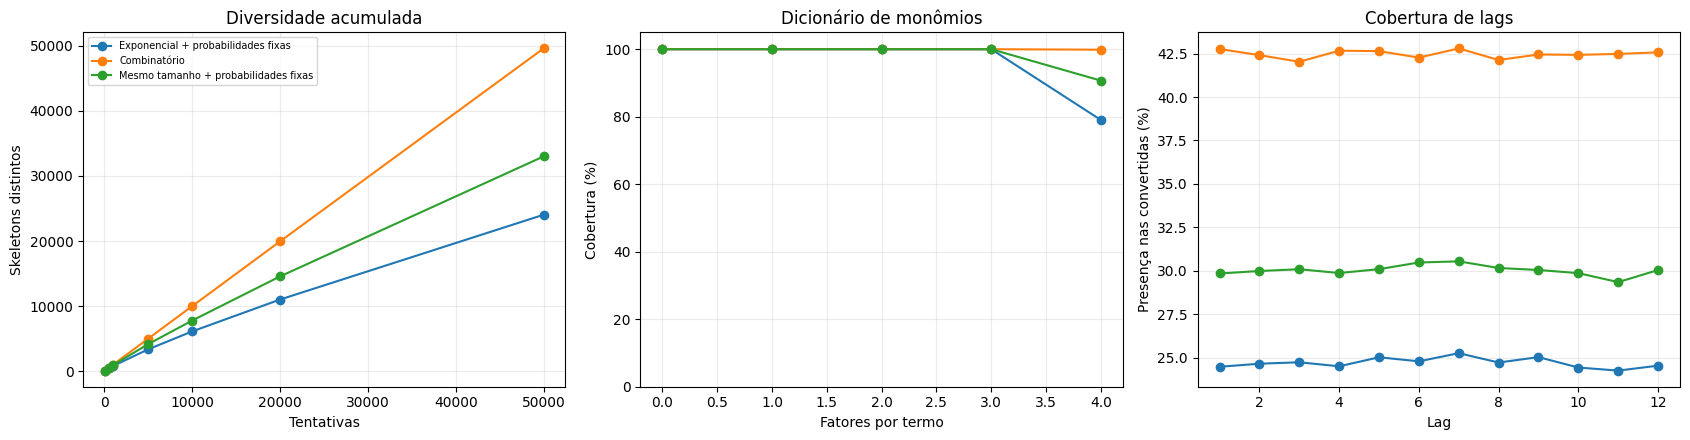

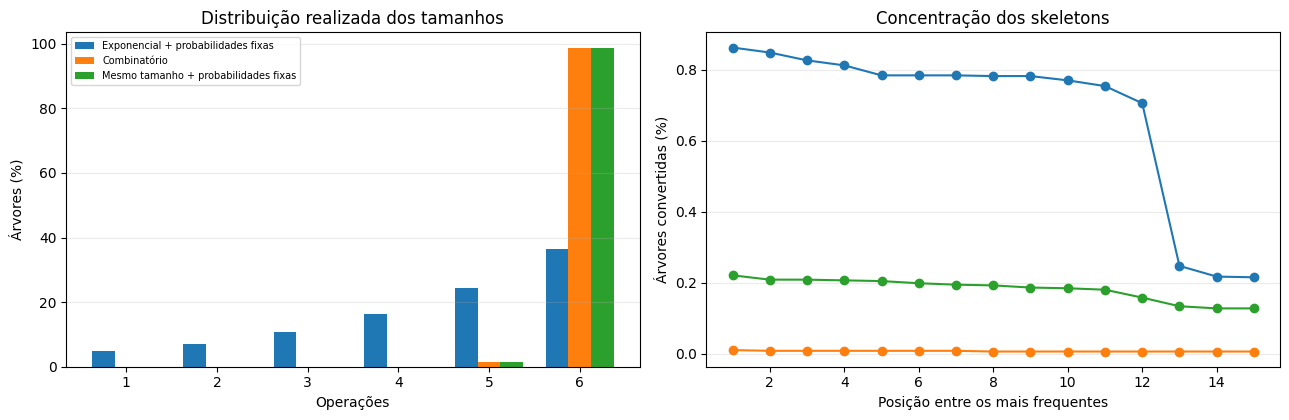

In [5]:
top_rows=[]
for method, st in stats.items():
    for rank,(key,value) in enumerate(sorted(st['supports'].items(), key=lambda kv:(-kv[1],kv[0]))[:TOP_N],1):
        top_rows.append({'Método':method,'Posição':rank,'Skeleton':support_formula(key),
            'Frequência':value,'Percentual (%)':100*value/st['accepted']})
top_df=pd.DataFrame(top_rows)
for method in METHODS:
    print(method)
    display(top_df[top_df['Método'].eq(method)].round(3))

fig,axes=plt.subplots(1,3,figsize=(17,4.5))
for method in METHODS:
    part=coverage_df[coverage_df['Método'].eq(method)]
    axes[0].plot(part['Gerações'],part['Skeletons distintos'],marker='o',label=method)
    part=factor_df[factor_df['Método'].eq(method)]
    axes[1].plot(part['Fatores por termo'],part['Cobertura (%)'],marker='o',label=method)
    part=lag_df[lag_df['Método'].eq(method)]
    axes[2].plot(part['Lag'],part['Presença nas convertidas (%)'],marker='o',label=method)
axes[0].set(xlabel='Tentativas',ylabel='Skeletons distintos',title='Diversidade acumulada')
axes[1].set(xlabel='Fatores por termo',ylabel='Cobertura (%)',title='Dicionário de monômios',ylim=(0,105))
axes[2].set(xlabel='Lag',ylabel='Presença nas convertidas (%)',title='Cobertura de lags')
for ax in axes:ax.grid(alpha=.25)
axes[0].legend(fontsize=7)
fig.tight_layout();plt.show()
fig,axes=plt.subplots(1,2,figsize=(13,4.3))
x=np.arange(1,7)
for j,method in enumerate(METHODS):
    axes[0].bar(x+(j-1)*.25,[100*stats[method]['size_counts'][int(k)]/SAMPLE_COUNT for k in x],width=.25,label=method)
    key=top_df[top_df['Método'].eq(method)]
    axes[1].plot(key['Posição'],key['Percentual (%)'],marker='o',label=method)
axes[0].set(xlabel='Operações',ylabel='Árvores (%)',title='Distribuição realizada dos tamanhos',xticks=x)
axes[1].set(xlabel='Posição entre os mais frequentes',ylabel='Árvores convertidas (%)',title='Concentração dos skeletons')
axes[0].legend(fontsize=7)
for ax in axes:ax.grid(axis='y',alpha=.25)
fig.tight_layout();plt.show()

**O que foi feito:** mostramos as fórmulas dos skeletons frequentes e cinco gráficos para distinguir diversidade, fatores, lags, tamanho das árvores e concentração.

## 5. Verificação com outras seeds

Repetimos a comparação principal com três seeds adicionais e 10.000 tentativas por método. Os limites e as probabilidades permanecem definidos pela mesma regra, sem ajuste a partir dessas execuções. Essa verificação mostra a sensibilidade à seed; três repetições e uma única configuração de vocabulário delimitam a conclusão.

In [6]:
ROBUSTNESS_SEEDS=(20261029,20261030,20261031)
ROBUSTNESS_COUNT=10_000
robustness_rows=[]
for root_seed in ROBUSTNESS_SEEDS:
    repeat,_=run_comparison(root_seed,ROBUSTNESS_COUNT,methods=(BASELINE,COUNTED),detailed=False)
    for method,st in repeat.items():
        robustness_rows.append({'Seed':root_seed,'Método':method,
            'Tentativas':ROBUSTNESS_COUNT,'Skeletons distintos':len(st['supports']),
            'Rejeitadas por grau':st['degree_rejected']})
robustness_df=pd.DataFrame(robustness_rows)
display(robustness_df)

,Seed,Método,Tentativas,Skeletons distintos,Rejeitadas por grau
0,20261029,Exponencial + probabilidades fixas,10000,6020,60
1,20261029,Combinatório,10000,9988,0
2,20261030,Exponencial + probabilidades fixas,10000,6128,64
3,20261030,Combinatório,10000,9988,0
4,20261031,Exponencial + probabilidades fixas,10000,6046,59
5,20261031,Combinatório,10000,9978,0


**O que foi feito:** medimos a diversidade em três sequências independentes adicionais, usando o mesmo orçamento de tentativas por método.

## 6. Resultado e alcance

A contagem favorece tamanhos grandes porque eles contêm muito mais ASTs possíveis. O controle de tamanho ajuda a interpretar esse efeito. A concentração das amostras em seis operações é uma consequência da prior uniforme sobre ASTs de todos os tamanhos permitidos; aplicações que precisem reservar espaço para mecanismos simples podem definir outra prior de tamanho explicitamente.

As contagens consideram um marcador estrutural de parâmetro contra 12 rótulos de lag. Esse tratamento influencia a frequência dos coeficientes e das dependências: menos folhas de parâmetro significa mais fatores com coeficiente implícito um. O aumento de diversidade estrutural deve ser considerado junto à distribuição de coeficientes desejada no benchmark. A contagem do método é exata para essa gramática discreta; a qualidade para um modelo ou para recuperar mecanismos precisa de avaliação própria.

Os resultados referem-se a uma série, lags 1–12, até seis operações e grau máximo quatro. A biblioteca aceita outras quantidades de séries e outros limites, mas os experimentos multivariados ficam para uma avaliação posterior. Esta avaliação mantém os skeletons repetidos e estuda a distribuição de expressões, antes da simulação de trajetórias e do treinamento de modelos.

In [7]:
base=summary_df.set_index('Método').loc[BASELINE]
new=summary_df.set_index('Método').loc[COUNTED]
control=summary_df.set_index('Método').loc[CONTROL]
gain=int(new['Skeletons distintos']-base['Skeletons distintos'])
gain_pct=100*gain/base['Skeletons distintos']
conclusion=(
    f"Com {SAMPLE_COUNT} tentativas, referência={int(base['Skeletons distintos'])}, "
    f"combinatório={int(new['Skeletons distintos'])}, controle de tamanho={int(control['Skeletons distintos'])}. "
    f"Diferença combinatório versus referência: {gain:+d} ({gain_pct:+.2f}%). "
    "Uniformidade comprovada sobre ASTs discretas válidas; diversidade de skeletons avaliada empiricamente."
)
print(conclusion)

Com 50000 tentativas, referência=24033, combinatório=49582, controle de tamanho=32994. Diferença combinatório versus referência: +25549 (+106.31%). Uniformidade comprovada sobre ASTs discretas válidas; diversidade de skeletons avaliada empiricamente.


**O que foi feito:** calculamos o ganho observado sem atribuir uma garantia de optimalidade sobre skeletons ao sorteio uniforme de ASTs.

## 7. Registro completo do experimento executado

In [8]:
source_paths=(
    'src/tsfmxai/generators/combinatorial_expression.py',
    'src/tsfmxai/generators/random_expression.py',
    'src/tsfmxai/representations/canonical_polynomial.py',
)
record={
    'question':'Completion-count sampling versus the previous best AST prior for skeleton diversity.',
    'configuration':{
        'baseline':asdict(BASE),'combinatorial':asdict(COMBINATORIAL),
        'exponential_slope':EXP_SLOPE,'methods':METHODS,'attempts_per_method':SAMPLE_COUNT,
        'checkpoints':CHECKPOINTS,'root_seed':ROOT_SEED,
        'robustness_seeds':ROBUSTNESS_SEEDS,'robustness_attempts':ROBUSTNESS_COUNT,
        'replacement':True,'skeleton_deduplication_during_sampling':False,
    },
    'provenance':{
        'sampler':'exact integer counting and uniform rank over ordered labelled ASTs',
        'tree_seeds':'derive_sample_seed(root_seed,index)',
        'baseline_size_seeds':'SeedSequence([root_seed,index,20261029])',
        'combinatorial_structure_rng':'local random.Random(tree_seed).randrange(total)',
        'combinatorial_coefficient_rng':'default_rng(SeedSequence([tree_seed,20261030]))',
        'source_sha256':{p:sha256((ROOT/p).read_bytes()).hexdigest() for p in source_paths},
        'git_head':subprocess.check_output(['git','rev-parse','HEAD'],cwd=ROOT,text=True).strip(),
        'working_tree_note':'Source hashes identify this experiment even if changes are uncommitted.',
        'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,
        'matplotlib':matplotlib.__version__,'platform':platform.platform(),
        'processor':platform.processor(),'external_data':None,
        'reference':'flajolet1994calculus; Zimmermann 2011 slides, PDF page 16',
    },
    'metrics':{
        'count_table':size_df.to_dict('records'),'marginal_profile':profile,
        'count_precomputation_seconds':INITIALIZATION_SECONDS,
        'summary':summary_df.to_dict('records'),'checkpoints':coverage_df.to_dict('records'),
        'realized_profiles':profile_df.to_dict('records'),'factor_coverage':factor_df.to_dict('records'),
        'lag_coverage':lag_df.to_dict('records'),'top_skeletons':top_df.to_dict('records'),
        'robustness':robustness_df.to_dict('records'),
    },
    'scientific_summary':conclusion,
    'reproduction':(
        '.venv\Scripts\python.exe -m jupyter nbconvert --to notebook --execute --inplace '
        '--ExecutePreprocessor.timeout=1200 '
        'experiments/canonicalization/combinatorial_prior/1_combinatorial_coverage.ipynb'
    ),
}
from pprint import pprint
pprint(record,sort_dicts=False)

{'question': 'Completion-count sampling versus the previous best AST prior for '
             'skeleton diversity.',
 'configuration': {'baseline': {'minimum_operators': 1,
                                'maximum_operators': 6,
                                'num_series': 1,
                                'minimum_lag': 1,
                                'maximum_lag': 12,
                                'parameter_probability': 0.4,
                                'lag_probability': 0.6,
                                'add_probability': 0.65,
                                'minimum_parameter_magnitude': 0.05,
                                'maximum_parameter_magnitude': 0.9,
                                'require_lag': True,
                                'coefficient_gate_lags': False},
                   'combinatorial': {'minimum_operators': 1,
                                     'maximum_operators': 6,
                                     'num_series': 1,
               

**O que foi feito:** registramos configuração, seeds, métricas, hashes das fontes, conclusão e comando de reprodução no próprio notebook.